In [42]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

In [43]:
df = pd.read_csv('traffic1.csv')
df.head()

,Time,Date,Day of the week,CarCount,BikeCount,BusCount,TruckCount,Total,Traffic Situation
0,12:00:00 AM,10,Tuesday,31,0,4,4,39,low
1,12:15:00 AM,10,Tuesday,49,0,3,3,55,low
2,12:30:00 AM,10,Tuesday,46,0,3,6,55,low
3,12:45:00 AM,10,Tuesday,51,0,2,5,58,low
4,1:00:00 AM,10,Tuesday,57,6,15,16,94,normal


In [44]:
df.shape

(2976, 9)

In [45]:
df.isnull().sum()

Time                 0
Date                 0
Day of the week      0
CarCount             0
BikeCount            0
BusCount             0
TruckCount           0
Total                0
Traffic Situation    0
dtype: int64

In [46]:
df.duplicated().sum()

np.int64(0)

In [47]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2976 entries, 0 to 2975
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   Time               2976 non-null   str  
 1   Date               2976 non-null   int64
 2   Day of the week    2976 non-null   str  
 3   CarCount           2976 non-null   int64
 4   BikeCount          2976 non-null   int64
 5   BusCount           2976 non-null   int64
 6   TruckCount         2976 non-null   int64
 7   Total              2976 non-null   int64
 8   Traffic Situation  2976 non-null   str  
dtypes: int64(6), str(3)
memory usage: 275.4 KB


In [48]:
df['Traffic Situation'].value_counts()

Traffic Situation
normal    1669
heavy      682
high       321
low        304
Name: count, dtype: int64

In [49]:
df.describe()

,Date,CarCount,BikeCount,BusCount,TruckCount,Total
count,2976.000000,2976.000000,2976.000000,2976.000000,2976.000000,2976.000000
mean,16.000000,68.696573,14.917339,15.279570,15.324933,114.218414
std,8.945775,45.850693,12.847518,14.341986,10.603833,60.190627
min,1.000000,6.000000,0.000000,0.000000,0.000000,21.000000
25%,8.000000,19.000000,5.000000,1.000000,6.000000,55.000000
50%,16.000000,64.000000,12.000000,12.000000,14.000000,109.000000
75%,24.000000,107.000000,22.000000,25.000000,23.000000,164.000000
max,31.000000,180.000000,70.000000,50.000000,40.000000,279.000000


EDA

<Axes: xlabel='Traffic Situation', ylabel='count'>

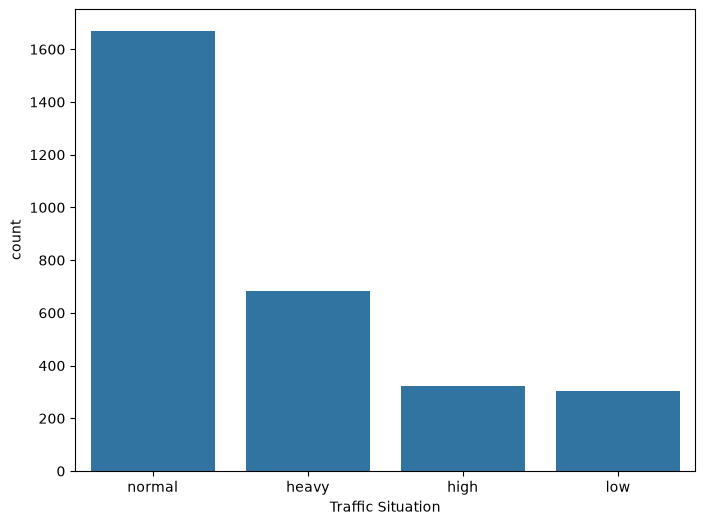

In [50]:
plt.figure(figsize=(8,6))
sns.countplot(
    data = df,
    x = 'Traffic Situation',
    order = df['Traffic Situation'].value_counts().index
)

In [51]:
vehicle_sum = (
    df['CarCount'] +
    df['BikeCount'] +
    df['BusCount'] +
    df['TruckCount']
)

print("Total matches vehicle sum:", (df['Total'] == vehicle_sum).all())

print("\nSample comparison:")
display(pd.DataFrame({
    'Actual Total': df['Total'].head(10),
    'Calculated Total': vehicle_sum.head(10)
}))

Total matches vehicle sum: True

Sample comparison:


,Actual Total,Calculated Total
0,39,39
1,55,55
2,55,55
3,58,58
4,94,94
5,53,53
6,42,42
7,55,55
8,67,67
9,45,45


In [52]:
print("All rows match:", (df['Total'] == vehicle_sum).all())

All rows match: True


In [53]:
print("Unique Time values:")
print(df['Time'].unique()[:20])

print("\nUnique Dates:")
print(sorted(df['Date'].unique()))

print("\nDays of the Week:")
print(df['Day of the week'].value_counts())

Unique Time values:
<ArrowStringArray>
['12:00:00 AM', '12:15:00 AM', '12:30:00 AM', '12:45:00 AM',  '1:00:00 AM',
  '1:15:00 AM',  '1:30:00 AM',  '1:45:00 AM',  '2:00:00 AM',  '2:15:00 AM',
  '2:30:00 AM',  '2:45:00 AM',  '3:00:00 AM',  '3:15:00 AM',  '3:30:00 AM',
  '3:45:00 AM',  '4:00:00 AM',  '4:15:00 AM',  '4:30:00 AM',  '4:45:00 AM']
Length: 20, dtype: str

Unique Dates:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31)]

Days of the Week:
Day of the week
Tuesday      480
Wednesday    480
Thursday     480
Friday       384
Saturday     384
Sunday       384
Monday       384
Name: count, dtype: int64


In [54]:
# Convert Time into datetime format
df['Time'] = pd.to_datetime(
    df['Time'],
    format='%I:%M:%S %p'
)

# Extract hour and minute
df['Hour'] = df['Time'].dt.hour
df['Minute'] = df['Time'].dt.minute

display(df[['Time', 'Hour', 'Minute']].head(10))

,Time,Hour,Minute
0,1900-01-01 00:00:00,0,0
1,1900-01-01 00:15:00,0,15
2,1900-01-01 00:30:00,0,30
3,1900-01-01 00:45:00,0,45
4,1900-01-01 01:00:00,1,0
5,1900-01-01 01:15:00,1,15
6,1900-01-01 01:30:00,1,30
7,1900-01-01 01:45:00,1,45
8,1900-01-01 02:00:00,2,0
9,1900-01-01 02:15:00,2,15


In [55]:
df.head()

,Time,Date,Day of the week,CarCount,BikeCount,BusCount,TruckCount,Total,Traffic Situation,Hour,Minute
0,1900-01-01 00:00:00,10,Tuesday,31,0,4,4,39,low,0,0
1,1900-01-01 00:15:00,10,Tuesday,49,0,3,3,55,low,0,15
2,1900-01-01 00:30:00,10,Tuesday,46,0,3,6,55,low,0,30
3,1900-01-01 00:45:00,10,Tuesday,51,0,2,5,58,low,0,45
4,1900-01-01 01:00:00,10,Tuesday,57,6,15,16,94,normal,1,0


One hot encoding

In [56]:
from sklearn.preprocessing import OneHotEncoder

In [57]:
encoder = OneHotEncoder(sparse_output=False)

In [58]:
days_encoded = encoder.fit_transform(df[["Day of the week"]])

In [59]:
day_df = pd.DataFrame(
    days_encoded,
    columns=encoder.get_feature_names_out(['Day of the week'])
)


In [60]:
day_df.head()

,Day of the week_Friday,Day of the week_Monday,Day of the week_Saturday,Day of the week_Sunday,Day of the week_Thursday,Day of the week_Tuesday,Day of the week_Wednesday
0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [61]:
df = pd.concat([df, day_df], axis =1)

In [62]:
df.drop('Day of the week', axis = 1, inplace= True)

In [63]:
display(df.head())
print("New Shape:", df.shape)

,Time,Date,CarCount,BikeCount,BusCount,TruckCount,Total,Traffic Situation,Hour,Minute,Day of the week_Friday,Day of the week_Monday,Day of the week_Saturday,Day of the week_Sunday,Day of the week_Thursday,Day of the week_Tuesday,Day of the week_Wednesday
0,1900-01-01 00:00:00,10,31,0,4,4,39,low,0,0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,1900-01-01 00:15:00,10,49,0,3,3,55,low,0,15,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,1900-01-01 00:30:00,10,46,0,3,6,55,low,0,30,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,1900-01-01 00:45:00,10,51,0,2,5,58,low,0,45,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,1900-01-01 01:00:00,10,57,6,15,16,94,normal,1,0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


New Shape: (2976, 17)


In [64]:
print("Column names:")
print(df.columns.tolist())

print("\nFirst row:")
print(df.iloc[0].to_dict())

print("\nData types:")
print(df.dtypes)

Column names:
['Time', 'Date', 'CarCount', 'BikeCount', 'BusCount', 'TruckCount', 'Total', 'Traffic Situation', 'Hour', 'Minute', 'Day of the week_Friday', 'Day of the week_Monday', 'Day of the week_Saturday', 'Day of the week_Sunday', 'Day of the week_Thursday', 'Day of the week_Tuesday', 'Day of the week_Wednesday']

First row:
{'Time': Timestamp('1900-01-01 00:00:00'), 'Date': 10, 'CarCount': 31, 'BikeCount': 0, 'BusCount': 4, 'TruckCount': 4, 'Total': 39, 'Traffic Situation': 'low', 'Hour': 0, 'Minute': 0, 'Day of the week_Friday': 0.0, 'Day of the week_Monday': 0.0, 'Day of the week_Saturday': 0.0, 'Day of the week_Sunday': 0.0, 'Day of the week_Thursday': 0.0, 'Day of the week_Tuesday': 1.0, 'Day of the week_Wednesday': 0.0}

Data types:
Time                         datetime64[us]
Date                                  int64
CarCount                              int64
BikeCount                             int64
BusCount                              int64
TruckCount                

In [65]:
df = df.drop(['Time', 'Total'], axis= 1)

In [66]:
df.head()

,Date,CarCount,BikeCount,BusCount,TruckCount,Traffic Situation,Hour,Minute,Day of the week_Friday,Day of the week_Monday,Day of the week_Saturday,Day of the week_Sunday,Day of the week_Thursday,Day of the week_Tuesday,Day of the week_Wednesday
0,10,31,0,4,4,low,0,0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,10,49,0,3,3,low,0,15,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,10,46,0,3,6,low,0,30,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,10,51,0,2,5,low,0,45,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,10,57,6,15,16,normal,1,0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [67]:
X = df.drop('Traffic Situation', axis = 1)
y = df['Traffic Situation']

In [68]:
print("\nFeatures:")
print(X.columns.tolist())

print("\nTarget Classes:")
print(y.unique())


Features:
['Date', 'CarCount', 'BikeCount', 'BusCount', 'TruckCount', 'Hour', 'Minute', 'Day of the week_Friday', 'Day of the week_Monday', 'Day of the week_Saturday', 'Day of the week_Sunday', 'Day of the week_Thursday', 'Day of the week_Tuesday', 'Day of the week_Wednesday']

Target Classes:
<ArrowStringArray>
['low', 'normal', 'heavy', 'high']
Length: 4, dtype: str


In [69]:
from sklearn.model_selection import train_test_split

In [70]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    random_state= 42, 
    test_size= 0.2
)

In [71]:
print(X_train.shape)
print(X_test.shape)

(2380, 14)
(596, 14)


In [72]:
from sklearn.preprocessing import StandardScaler

In [73]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [74]:
from sklearn.preprocessing import LabelEncoder

In [75]:
labelencoder = LabelEncoder()

y_train_encoded = labelencoder.fit_transform(y_train)
y_test_encoded = labelencoder.transform(y_test)

In [76]:
import tensorflow as tf
import keras_tuner as kt
from tensorflow import keras
from tensorflow.keras.models import Sequential
from keras.layers import Dense, Dropout

In [77]:
def build_model(hp):
    model = Sequential()

    num_layers = hp.Int("num_layers", min_value= 1, max_value = 5)

    for i in range(num_layers):
        units = hp.Int(
            f'units_{i}',
            min_value = 14, 
            max_value = 128
        )

        activation = hp.Choice(
            f'activation_{i}',
            values = ['relu', 'tanh', 'elu']
        )

        model.add(Dense(units= units, activation= activation,
                        input_dim= 14))

        drop_out = hp.Choice(
            f'dropout_{i}',
            values = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]
        )

        model.add(Dropout(drop_out))

    model.add(Dense(4, activation= 'softmax'))
    optimizer = hp.Choice(
        'optimizer', values = ['adam', 'rmsprop', 'sgd', 'nadams', 'adadelta']
    )

    model.compile(
        optimizer = optimizer,
        loss = 'sparse_categorical_crossentropy',
        metrics = ['accuracy']
    )

    return model


In [78]:
tuner = kt.RandomSearch(
    build_model,
    objective= 'val_accuracy',
    max_trials= 10, 
    overwrite = True,
    directory = 'tuning',
    project_name = 'traffic_tuninng'
)

In [79]:
tuner.search(X_train_scaled, y_train_encoded, epochs = 5, validation_data = (X_test_scaled, y_test_encoded))

Trial 10 Complete [00h 00m 02s]
val_accuracy: 0.7013422846794128

Best val_accuracy So Far: 0.8976510167121887
Total elapsed time: 00h 00m 20s


In [80]:
tuner.get_best_hyperparameters()[0].values

{'num_layers': 5,
 'units_0': 76,
 'activation_0': 'tanh',
 'dropout_0': 0.2,
 'optimizer': 'adam',
 'units_1': 54,
 'activation_1': 'relu',
 'dropout_1': 0.0,
 'units_2': 22,
 'activation_2': 'elu',
 'dropout_2': 0.0,
 'units_3': 58,
 'activation_3': 'elu',
 'dropout_3': 0.0,
 'units_4': 90,
 'activation_4': 'elu',
 'dropout_4': 0.3}

In [82]:
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]

In [83]:
model = build_model(best_hp)

In [84]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 76)             │         1,140 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 76)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 54)             │         4,158 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 54)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 22)             │         1,210 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 22)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 58)             │         1,334 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 58)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 90)             │         5,310 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 90)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 4)              │           364 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,516 (52.80 KB)

 Trainable params: 13,516 (52.80 KB)

 Non-trainable params: 0 (0.00 B)

In [85]:
history = model.fit(
    X_train_scaled,
    y_train_encoded,
    epochs=100,
    validation_split=0.2,
    batch_size=32,
    validation_data = (X_test_scaled, y_test_encoded)
)

Epoch 1/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7244 - loss: 0.7579 - val_accuracy: 0.7735 - val_loss: 0.5416
Epoch 2/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8134 - loss: 0.4644 - val_accuracy: 0.8406 - val_loss: 0.4304
Epoch 3/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8500 - loss: 0.3735 - val_accuracy: 0.8658 - val_loss: 0.3521
Epoch 4/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8714 - loss: 0.3253 - val_accuracy: 0.8792 - val_loss: 0.3113
Epoch 5/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8727 - loss: 0.3060 - val_accuracy: 0.8792 - val_loss: 0.3041
Epoch 6/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8878 - loss: 0.2848 - val_accuracy: 0.8893 - val_loss: 0.2788
Epoch 7/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8887 - loss: 0.2733 - val_accuracy: 0.9178 - val_loss: 0.2366
Epoch 8/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9025 - loss: 0.2416 - val_accuracy: 0.9195 - v

In [86]:
test_loss, test_accuracy = model.evaluate(
    X_test_scaled,
    y_test_encoded
)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9430 - loss: 0.2288 
Test Accuracy: 0.9429529905319214
Test Loss: 0.22879041731357574


19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


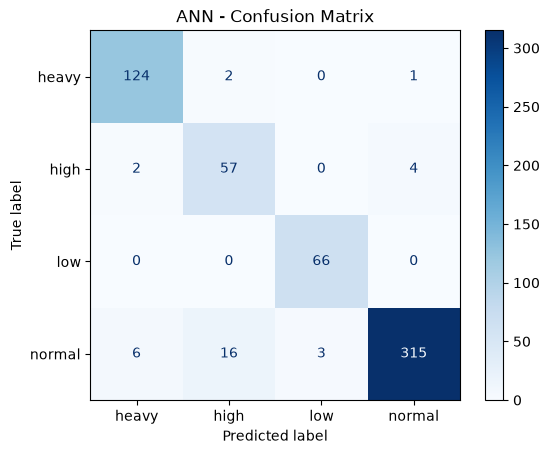

In [88]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

y_pred = model.predict(X_test_scaled)

y_pred = np.argmax(y_pred, axis=1)

cm = confusion_matrix(y_test_encoded, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labelencoder.classes_
)

disp.plot(cmap='Blues')
plt.title('ANN - Confusion Matrix')
plt.show()

In [89]:
model.save('traffic_classification_model.keras')

In [90]:
import joblib

joblib.dump(scaler, 'scaler.pkl')

['scaler.pkl']

In [91]:
joblib.dump(labelencoder, 'label_encoder.pkl')

['label_encoder.pkl']

In [92]:
joblib.dump(encoder, 'day_encoder.pkl')

['day_encoder.pkl']